# 07 · Dense ESG v2 — 전처리 재현·검증 → **Gate 1**

> 컨트롤러: [`plan/AGENT.md`](../plan/AGENT.md) · 상세: [`plan/04_preprocessing.md`](../plan/04_preprocessing.md)
> 베이스라인(개선 전): [`06_dence_cosine.ipynb`](06_dence_cosine.ipynb) — **건드리지 않는다**(§7.1 전/후 비교용).

**이 노트북의 범위 = Step 1 + Step 2(전처리)까지.**
임베딩·화이트닝·앵커·풀링·회귀는 **Gate 1 PASS 이전 금지**(`AGENT.md` §6). 여기서는
사업보고서 `II·IV·VI` 본문을 **문장 단위**로 깨끗하게 만드는 데까지만 한다.

**모든 코드 셀 = 3종 세트** — ① 시각화 ② 실제 샘플 1~2건 ③ 해석 가이드.
각 단계 끝에서 **PASS / FAIL / REVIEW REQUIRED** 를 선언한다.

### 반복 개선 이력 (§4-0 루프)
- **Round 1** — 06 baseline 전처리(§4.1)를 그대로 재현 → **Gate 1 기준3(초장문) FAIL** 발견.
  Kiwi `split_into_sents()` 가 표 섞인 거대 입력(최장 222,465자, 본문의 95%)에서 segmentation 붕괴.
  종결부호(`다.` 914개)는 있는데도 한 덩어리로 반환 → 마침표 부재 문제가 아니라 **Kiwi에 거대 입력**이 원인.
- **Round 2 (현재)** — 문장분할만 교체: **거친 청크 → 작은 조각만 Kiwi → (안 되면) 마침표/`입니다` 수동 분할 → 최후 길이상한 절단.**
  섹션추출·경량클리닝(§4.1)은 그대로 유지.

| 단계 | 내용 |
|---|---|
| Step 1 | 환경·상수·데이터 로드 (키 매칭률·결측 요약 + 상위 5행) |
| Step 2 | 전처리(섹션추출→경량클리닝→**개선된 문장분할**) + 3유형 샘플 검증 + before/after → **Gate 1** |


## Step 1 — 환경 · 상수 · 데이터 로드

`dart_preprocessed.csv`(원문 `raw_text` 보존본)와 `company_master.csv`(키·등급·업종)를
**`company_name + esg_year`** 로 1:1 조인해 `stock_code/fiscal_year/industry/등급`을 복원한다.
회사명 단독 merge 금지 · `validate='one_to_one'` · 키 결측/중복 assert.

In [1]:
# ── Step 1.1 · 환경 · import · 상수 ─────────────────────────────────────
# [임베딩 미포함] torch / sentence-transformers 는 일부러 import 하지 않는다 (Gate 1 전 금지).
import re, time, unicodedata, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams
try:
    import seaborn as sns
except ImportError as e:
    raise ImportError("seaborn 미설치 → uv add seaborn") from e
from kiwipiepy import Kiwi

# 한글 폰트 자동 선택 (mac=AppleGothic, win=Malgun Gothic, Colab=NanumGothic)
_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _f in ['AppleGothic', 'Malgun Gothic', 'NanumGothic', 'NanumBarunGothic']:
    if _f in _fonts:
        rcParams['font.family'] = _f; break
rcParams['axes.unicode_minus'] = False

# 경로
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PREPROCESSED_CSV = DATA_PROCESSED / 'dart_preprocessed.csv'
COMPANY_MASTER_CSV = DATA_RAW / 'company_master.csv'
SENT_CACHE = DATA_PROCESSED / '07_v2_sentences.parquet'   # 문장분할 캐시(CLEAN_VERSION으로 무효화)
for p in [PREPROCESSED_CSV, COMPANY_MASTER_CSV]:
    assert p.exists(), f'필수 입력 누락: {p}'

# ── 상수 (§4.1 핵심 상수 + Round2 문장분할 상수) ──
ESG_DIMS = ['E', 'S', 'G']
GRADE_MAP = {'S': 6, 'A+': 5, 'A': 4, 'B+': 3, 'B': 2, 'C': 1, 'D': 0}
KEY_COLS = ['stock_code', 'fiscal_year']
STRICT_KEY_COLS = ['stock_code', 'fiscal_year', 'esg_year']
CORE_SECTIONS = ['II', 'IV', 'VI']   # 사업의 내용 / 경영진단(MD&A) / 이사회 등
MIN_SENT_CHARS = 10                  # 이보다 짧은 문장 제거
MAX_SENT_CHARS = 1000                # [Round2] 이보다 긴 '문장'=Kiwi 분할실패 → 재분할/절단 (정상 한국어 p99≈999)
KIWI_CHUNK = 2000                    # [Round2] Kiwi 한 번 입력 최대 길이 (거대 표덩어리 segmentation 붕괴 방지)
MODEL_NAME = 'nlpai-lab/KURE-v1'     # (참고용 — 이 노트북에선 로드하지 않음)
CLEAN_VERSION = 'v2-chunked-kiwi'    # [Round2] 문장분할 교체 → baseline 캐시 무효화

print('PROJECT_ROOT :', PROJECT_ROOT)
print('matplotlib 폰트 :', rcParams['font.family'])
print('핵심 섹션 :', CORE_SECTIONS, '| MIN/MAX_SENT :', MIN_SENT_CHARS, '/', MAX_SENT_CHARS,
      '| KIWI_CHUNK :', KIWI_CHUNK, '| 모델(참고) :', MODEL_NAME)
print('전처리 버전 :', CLEAN_VERSION, ' (Round1=baseline 재현·버그발견 → Round2=청크→Kiwi+수동폴백)')

# ── 해석 가이드 ──
print('\n[해석 가이드] 이 셀은 환경/상수만 정의한다. 폰트가 비어 그래프 한글이 깨지면 위 폰트 목록을 확인.'
      '\n  임베딩 라이브러리를 일부러 빼둔 이유: Gate 1(전처리) 통과 전 임베딩 금지(AGENT §6).'
      '\n  Round2 핵심: 문장분할만 교체(섹션추출·클리닝은 §4.1 그대로). MODEL 재사용 OK, 캐시 재사용 ✗.')

PROJECT_ROOT : /Users/home1/esg-dart-project
matplotlib 폰트 : ['AppleGothic']
핵심 섹션 : ['II', 'IV', 'VI'] | MIN/MAX_SENT : 10 / 1000 | KIWI_CHUNK : 2000 | 모델(참고) : nlpai-lab/KURE-v1
전처리 버전 : v2-chunked-kiwi  (Round1=baseline 재현·버그발견 → Round2=청크→Kiwi+수동폴백)

[해석 가이드] 이 셀은 환경/상수만 정의한다. 폰트가 비어 그래프 한글이 깨지면 위 폰트 목록을 확인.
  임베딩 라이브러리를 일부러 빼둔 이유: Gate 1(전처리) 통과 전 임베딩 금지(AGENT §6).
  Round2 핵심: 문장분할만 교체(섹션추출·클리닝은 §4.1 그대로). MODEL 재사용 OK, 캐시 재사용 ✗.


키 매칭률: 381/381 = 100.0%  (매칭 실패 0건)
연도별 문서 수: {2022: 127, 2023: 127, 2024: 127}
업종 고유값 수: 22

▶ 결측 요약:


,결측수,결측률
industry,297,78.0
esg_grade,0,0.0
e_grade,0,0.0
s_grade,0,0.0
g_grade,0,0.0


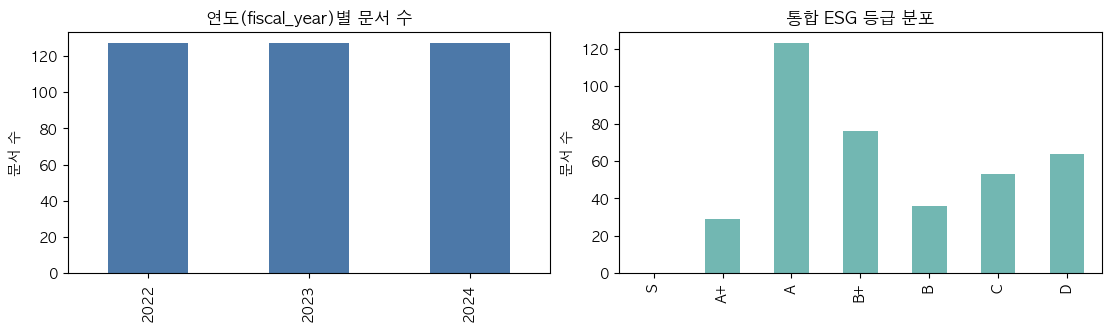


▶ 상위 5행:


,company_name,stock_code,fiscal_year,esg_year,industry,esg_grade,e_grade,s_grade,g_grade
0,동화약품,000020,2022,2023,NaN,C,C,B,C
1,동화약품,000020,2023,2024,NaN,C,B,B,C
2,동화약품,000020,2024,2025,NaN,C,B,C,C
3,KR모터스,000040,2022,2023,NaN,D,D,D,D
4,KR모터스,000040,2023,2024,NaN,D,D,D,D


[해석 가이드]
 • 키 매칭률 100% + 매칭 실패 0건 → 381 기업-연도 모두 등급에 안전하게 붙었다(정상).
 • esg_grade/e·s·g 등급 결측 0 → 회귀 종속변수는 온전. 단 industry 결측률 높음:
   ↳ AGENT §11 BLOCKER 와 연결 — 업종 통제는 data/processed/company_controls.csv 로 보완 필요(회귀 단계).
 • 연도별 127/127/127 균형 → 패널 불균형 없음. 등급은 A/B+ 에 몰린 약한 불균형(정상 범위).


In [2]:
# ── Step 1.2 · 데이터 로드 · 키 복원 · 매칭률/결측 요약 ──────────────────
preprocessed = pd.read_csv(PREPROCESSED_CSV, usecols=['회사이름', 'esg_year', 'raw_text'])
master = pd.read_csv(COMPANY_MASTER_CSV, dtype={'stock_code': 'string'})

preprocessed = preprocessed.rename(columns={'회사이름': 'company_name'}).copy()
preprocessed['company_name'] = preprocessed['company_name'].astype(str).str.strip()
preprocessed['esg_year'] = preprocessed['esg_year'].astype(int)
assert preprocessed['raw_text'].notna().all(), 'raw_text 결측'
preprocessed['raw_text'] = preprocessed['raw_text'].astype(str)
assert preprocessed.duplicated(['company_name', 'esg_year']).sum() == 0, '전처리본 company+esg_year 중복'

master['company_name'] = master['company_name'].astype(str).str.strip()
master['stock_code'] = (master['stock_code'].astype('string')
                        .str.replace(r'\.0$', '', regex=True).str.zfill(6))
master['fiscal_year'] = master['fiscal_year'].astype(int)
master['esg_year'] = master['esg_year'].astype(int)
assert master.duplicated(['company_name', 'esg_year']).sum() == 0, 'master company+esg_year 중복'
assert master.duplicated(KEY_COLS).sum() == 0, 'master stock+fiscal 중복'

mk = ['company_name', 'stock_code', 'fiscal_year', 'esg_year',
      'industry', 'esg_grade', 'e_grade', 's_grade', 'g_grade']
corpus_df = preprocessed.merge(master[mk], on=['company_name', 'esg_year'],
                               how='left', validate='one_to_one', indicator=True)
n_match = int((corpus_df['_merge'] == 'both').sum())
miss = corpus_df.loc[corpus_df['_merge'] != 'both', ['company_name', 'esg_year']]
assert miss.empty, '키 복원 실패:\n' + miss.to_string(index=False)
corpus_df = corpus_df.drop(columns='_merge').sort_values(KEY_COLS).reset_index(drop=True)
assert corpus_df[STRICT_KEY_COLS].notna().all().all(), '복원 키 결측'
assert corpus_df.duplicated(KEY_COLS).sum() == 0, '복원 후 PK 중복'

# 등급 → 숫자
for d in ESG_DIMS:
    corpus_df[f'{d.lower()}_grade_num'] = corpus_df[f'{d.lower()}_grade'].map(GRADE_MAP)
corpus_df['esg_grade_num'] = corpus_df['esg_grade'].map(GRADE_MAP)

# 결측 요약표
miss_cols = ['industry', 'esg_grade', 'e_grade', 's_grade', 'g_grade']
miss_tbl = pd.DataFrame({'결측수': corpus_df[miss_cols].isna().sum(),
                         '결측률': (corpus_df[miss_cols].isna().mean()*100).round(1)})

print(f'키 매칭률: {n_match}/{len(corpus_df)} = {n_match/len(corpus_df):.1%}  (매칭 실패 {len(miss)}건)')
print('연도별 문서 수:', corpus_df['fiscal_year'].value_counts().sort_index().to_dict())
print('업종 고유값 수:', corpus_df['industry'].nunique())
print('\n▶ 결측 요약:'); display(miss_tbl)

# ── ① 시각화: 연도별 문서 수 + 통합등급 분포 ──
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
corpus_df['fiscal_year'].value_counts().sort_index().plot(kind='bar', ax=ax[0], color='#4C78A8')
ax[0].set_title('연도(fiscal_year)별 문서 수'); ax[0].set_xlabel(''); ax[0].set_ylabel('문서 수')
order = ['S','A+','A','B+','B','C','D']
corpus_df['esg_grade'].value_counts().reindex(order).plot(kind='bar', ax=ax[1], color='#72B7B2')
ax[1].set_title('통합 ESG 등급 분포'); ax[1].set_xlabel(''); ax[1].set_ylabel('문서 수')
plt.savefig(FIGURES_DIR / '07_step1_overview.png', dpi=110); plt.show()

# ── ② 샘플: 상위 5행 ──
print('\n▶ 상위 5행:')
display(corpus_df[['company_name','stock_code','fiscal_year','esg_year','industry','esg_grade',
                   'e_grade','s_grade','g_grade']].head())

# ── ③ 해석 가이드 ──
print('[해석 가이드]')
print(' • 키 매칭률 100% + 매칭 실패 0건 → 381 기업-연도 모두 등급에 안전하게 붙었다(정상).')
print(' • esg_grade/e·s·g 등급 결측 0 → 회귀 종속변수는 온전. 단 industry 결측률 높음:')
print('   ↳ AGENT §11 BLOCKER 와 연결 — 업종 통제는 data/processed/company_controls.csv 로 보완 필요(회귀 단계).')
print(' • 연도별 127/127/127 균형 → 패널 불균형 없음. 등급은 A/B+ 에 몰린 약한 불균형(정상 범위).')

## Step 2 — 전처리 재현/개선 + 샘플 검증 → Gate 1

> ⚠️ TF-IDF 트랙과 다르다. **형태소 분석을 하지 않고 문장 구조를 보존**한다. 입력은 `raw_text`(섹션 머리글 보존).
> 파이프라인: **1/3 섹션 추출(II/IV/VI)** → **2/3 경량 클리닝** → **3/3 문장 분할**.
> 섹션추출·클리닝은 §4.1 그대로. 문장분할만 Round2에서 **청크→Kiwi+수동폴백**으로 교체했다.

▶ 핵심 섹션 보유 조합(present_core):
present_core
II+IV+VI    381

▶ 섹션별 문자 길이 요약:


,II,IV,VI
count,381,381,381
mean,44554,14705,15588
std,45158,17033,8811
min,2364,1025,279
25%,20425,6279,9306
50%,30066,10245,13902
75%,49513,16332,19151
max,293531,189671,58200


/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_9421/4154932191.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([sec_len[s].clip(lower=1) for s in CORE_SECTIONS], labels=CORE_SECTIONS, vert=True)


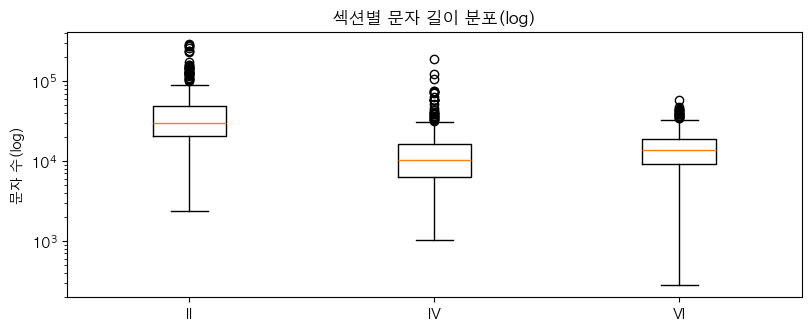


▶ 샘플 [동화약품 FY2022] 보유 섹션: ['II', 'IV', 'VI', 'VIII', 'XI'] | II/IV/VI 길이: {'II': 28480, 'IV': 5649, 'VI': 7555}

[해석 가이드]
 • present_core 가 모두 "II+IV+VI" 여야 정상(섹션 누락 0). 다른 조합이 보이면 머리글 정규식 점검.
 • II(사업의 내용)가 대체로 가장 길고 VI(이사회 등 지배구조)도 큼. IV(MD&A)는 중간.
 • 길이 편차가 매우 큰 것은 정상(지주·금융사 본문이 김). 다음 클리닝/분할이 이 길이를 어떻게 다루는지가 관건.


In [3]:
# ── Step 2.1 · 핵심 섹션(II/IV/VI) 추출 〔전처리 1/3 · §4.1 그대로〕 ──────
HEADER_RE = re.compile(r'(?m)^\s*(VIII|VII|XII|XI|IX|VI|IV|III|II|V|X|I)\.\s')

def split_sections(raw: str) -> dict:
    # 줄머리 로마숫자 머리글로 섹션 본문을 나눈다 -> {roman: 본문}
    matches = list(HEADER_RE.finditer(raw))
    out = {}
    for i, m in enumerate(matches):
        roman = m.group(1)
        end = matches[i + 1].start() if i + 1 < len(matches) else len(raw)
        out.setdefault(roman, []).append(raw[m.start():end])
    return {k: '\n'.join(v) for k, v in out.items()}

sections_per_doc = corpus_df['raw_text'].map(split_sections)
corpus_df['present_core'] = sections_per_doc.map(lambda d: '+'.join(s for s in CORE_SECTIONS if s in d))
corpus_df['core_raw'] = sections_per_doc.map(lambda d: '\n'.join(d[s] for s in CORE_SECTIONS if s in d))
corpus_df['core_raw_len'] = corpus_df['core_raw'].str.len()
assert (corpus_df['core_raw_len'] > 0).all(), 'II/IV/VI 추출 실패 행 존재'

sec_len = pd.DataFrame({s: sections_per_doc.map(lambda d, s=s: len(d.get(s, ''))) for s in CORE_SECTIONS})

print('▶ 핵심 섹션 보유 조합(present_core):')
print(corpus_df['present_core'].value_counts().to_string())
print('\n▶ 섹션별 문자 길이 요약:'); display(sec_len.describe().round(0).astype('Int64'))

# ── ① 시각화: 섹션별 길이 분포(로그) ──
fig, ax = plt.subplots(figsize=(8, 3.2), constrained_layout=True)
ax.boxplot([sec_len[s].clip(lower=1) for s in CORE_SECTIONS], labels=CORE_SECTIONS, vert=True)
ax.set_yscale('log'); ax.set_title('섹션별 문자 길이 분포(log)'); ax.set_ylabel('문자 수(log)')
plt.savefig(FIGURES_DIR / '07_step2_section_len.png', dpi=110); plt.show()

# ── ② 샘플: 첫 문서의 섹션 분해 ──
_s = split_sections(corpus_df.iloc[0]['raw_text'])
print(f"\n▶ 샘플 [{corpus_df.iloc[0]['company_name']} FY{corpus_df.iloc[0]['fiscal_year']}] 보유 섹션:",
      list(_s.keys()), '| II/IV/VI 길이:', {k: len(_s.get(k,'')) for k in CORE_SECTIONS})

# ── ③ 해석 가이드 ──
print('\n[해석 가이드]')
print(' • present_core 가 모두 "II+IV+VI" 여야 정상(섹션 누락 0). 다른 조합이 보이면 머리글 정규식 점검.')
print(' • II(사업의 내용)가 대체로 가장 길고 VI(이사회 등 지배구조)도 큼. IV(MD&A)는 중간.')
print(' • 길이 편차가 매우 큰 것은 정상(지주·금융사 본문이 김). 다음 클리닝/분할이 이 길이를 어떻게 다루는지가 관건.')

▶ 클리닝 제거 문자 비율 요약:


count    381.0000
mean       0.2465
std        0.0534
min        0.1343
25%        0.2051
50%        0.2452
75%        0.2884
max        0.4351
dtype: float64

전체 문자 28,517,680 -> 21,501,767 (24.6% 감소) | 깨진문자(�) 잔여 0


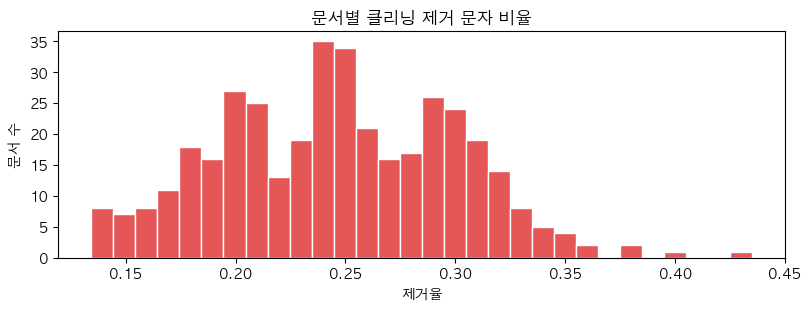


▶ 기호 최다 문서 [KB금융 FY2024] before/after (앞 320자)
--- BEFORE ---
 II. 사업의 내용

1. 사업의 개요

가. 사업의 내용(요약)

당사는 금융업을 영위하는 회사 등에 대한 지배ㆍ경영관리, 종속회사에 대한 자금지원 등을 주요사업 목적으로 하는 순수 지주회사로서, 금융의 새로운 패러다임을 제시하고 시장을 선도하는 리딩금융그룹이 되기 위해 모든 역량을 집중하고 있습니다. 또한 국내 최대 고객 기반을 바탕으로 은행업, 금융투자업, 보험업, 여신전문업 등 금융의 전 영역에서 선도적인 영업활동과 함께, 그룹 내 계열사간 시너지 창출을 통해 시장 지배력을 확대하고 있습니다. 한편, KB금융그룹의 2024년 조달 및 운용 평균잔액은 739조원
--- AFTER  ---
 II. 사업의 내용 사업의 개요 사업의 내용(요약) 당사는 금융업을 영위하는 회사 등에 대한 지배ᆞ경영관리, 종속회사에 대한 자금지원 등을 주요사업 목적으로 하는 순수 지주회사로서, 금융의 새로운 패러다임을 제시하고 시장을 선도하는 리딩금융그룹이 되기 위해 모든 역량을 집중하고 있습니다. 또한 국내 최대 고객 기반을 바탕으로 은행업, 금융투자업, 보험업, 여신전문업 등 금융의 전 영역에서 선도적인 영업활동과 함께, 그룹 내 계열사간 시너지 창출을 통해 시장 지배력을 확대하고 있습니다. 한편, KB금융그룹의 2024년 조달 및 운용 평균잔액은 739조원으로 2023년 

[해석 가이드]
 • 제거율 15~45%면 표/괘선/머리글 정리가 정상 작동. 깨진문자 잔여 0 이어야 함.
 • 알려진 경미한 부작용(미수정): NUM_RUN_RE 가 본문에 붙은 큰 금액을 깎을 수 있다.
   예) "3,498,014백만원" → "4백만원". ESG cosine 영향은 작아 §4.1 방침대로 유지(추후 필요시 보정).
 • SOFT_NEWLINE_RE 는 §4.1 그대로 둔다 — 초장문의 진짜 원인은 줄바꿈 결합이 아니라 Kiwi였음(2.4 참고).


In [4]:
# ── Step 2.2 · 경량 클리닝 〔전처리 2/3 · §4.1 그대로〕 ───────────────────
# 방침(§4.1): 문장을 통째로 버리는 필터는 두지 않는다(표/재무 문장은 cosine이 낮게 줘 자연히 묻힘).
#            ①깨진/표 문자 ②번호 머리글 ③숫자 잔재 ④표로 끊긴 줄바꿈만 정리. (06 baseline 규칙 그대로)
ROMAN = r'(?:VIII|VII|XII|XI|IX|VI|IV|III|II|V|X|I)'
REPLACEMENT_RE = re.compile(r'[�\x00-\x08\x0b\x0c\x0e-\x1f]')
BOX_RE = re.compile(r'[─━│┃┌┐└┘├┤┬┴┼═║╔╗╚╝▶◀▲▼◁▷■□●○◎◆◇★☆※→←↑↓]+')
SYMBOL_RUN_RE = re.compile(r'([^\w가-힣\s.?!])\1{2,}')
CIRCLED_BULLET_RE = re.compile(r'(?m)^[ \t]*[①-⑳㉠-㉭⑴-⒇][ \t]*')
HANGUL_BULLET_RE = re.compile(r'(?m)^[ \t]*[가-힣][.)][ \t]*')
DIGIT_BULLET_RE = re.compile(rf'(?m)^[ \t]*(?!{ROMAN}\.)\d{{1,2}}[.)][ \t]*')
PAREN_BULLET_RE = re.compile(r'(?m)^[ \t]*[(（]\s*[0-9가-힣]{1,3}\s*[)）][ \t]*')
NUM_RUN_RE = re.compile(r'(?<![가-힣A-Za-z])[\(\-\d][\d,.\(\)\-\s]{4,}(?![가-힣A-Za-z])')
SOFT_NEWLINE_RE = re.compile(
    rf'(?<![.?!])\n(?![ \t]*(?:{ROMAN}\.|\d+[.)]|[가-힣][.)]|[(（]|[①-⑳]))')
MULTISPACE_RE = re.compile(r'[ \t ]+')
MULTINEWLINE_RE = re.compile(r'\n{2,}')

def clean_light(text: str) -> str:
    text = REPLACEMENT_RE.sub(' ', text)
    text = BOX_RE.sub(' ', text)
    text = SYMBOL_RUN_RE.sub(r'\1', text)
    text = CIRCLED_BULLET_RE.sub('', text)          # 원형숫자는 NFKC '전에' 제거
    text = unicodedata.normalize('NFKC', text)      # 전각→반각
    text = HANGUL_BULLET_RE.sub('', text)
    text = DIGIT_BULLET_RE.sub('', text)
    text = PAREN_BULLET_RE.sub('', text)
    text = NUM_RUN_RE.sub(' ', text)                # 표에서 떨어진 숫자 나열 축소
    text = SOFT_NEWLINE_RE.sub(' ', text)           # 표로 끊긴 줄바꿈 잇기
    text = MULTISPACE_RE.sub(' ', text)
    text = MULTINEWLINE_RE.sub('\n', text)
    return text.strip()

corpus_df['core_text'] = corpus_df['core_raw'].map(clean_light)
corpus_df['core_len_chars'] = corpus_df['core_text'].str.len()
assert (corpus_df['core_len_chars'] > 0).all(), '클리닝 후 빈 문서 발생'
reduction = 1 - corpus_df['core_len_chars'] / corpus_df['core_raw_len']

print('▶ 클리닝 제거 문자 비율 요약:'); display(reduction.describe().round(4))
print(f'전체 문자 {int(corpus_df["core_raw_len"].sum()):,} -> {int(corpus_df["core_len_chars"].sum()):,}'
      f' ({reduction.mean():.1%} 감소) | 깨진문자(�) 잔여 {int(corpus_df["core_text"].str.count("�").sum())}')

# ── ① 시각화: 문서별 제거율 분포 ──
fig, ax = plt.subplots(figsize=(8, 3.0), constrained_layout=True)
ax.hist(reduction, bins=30, color='#E45756', edgecolor='white')
ax.set_title('문서별 클리닝 제거 문자 비율'); ax.set_xlabel('제거율'); ax.set_ylabel('문서 수')
plt.savefig(FIGURES_DIR / '07_step2_clean_reduction.png', dpi=110); plt.show()

# ── ② 샘플: '가장 지저분한' 문서 before/after ──
NONWORD_RE = re.compile(r'[^\w가-힣\s]')
messy_idx = corpus_df['core_raw'].map(lambda t: len(NONWORD_RE.findall(t))).idxmax()
r = corpus_df.loc[messy_idx]
print(f"\n▶ 기호 최다 문서 [{r['company_name']} FY{r['fiscal_year']}] before/after (앞 320자)")
print('--- BEFORE ---\n', r['core_raw'][:320])
print('--- AFTER  ---\n', r['core_text'][:320])

# ── ③ 해석 가이드 ──
print('\n[해석 가이드]')
print(' • 제거율 15~45%면 표/괘선/머리글 정리가 정상 작동. 깨진문자 잔여 0 이어야 함.')
print(' • 알려진 경미한 부작용(미수정): NUM_RUN_RE 가 본문에 붙은 큰 금액을 깎을 수 있다.')
print('   예) "3,498,014백만원" → "4백만원". ESG cosine 영향은 작아 §4.1 방침대로 유지(추후 필요시 보정).')
print(' • SOFT_NEWLINE_RE 는 §4.1 그대로 둔다 — 초장문의 진짜 원인은 줄바꿈 결합이 아니라 Kiwi였음(2.4 참고).')

▶ 3유형 고정 샘플:


,유형,company,FY,core_raw_len,nonword,sections
0,평균(중앙값 길이),HD현대인프라코어,2023,58475,4490,II+IV+VI
1,최악(기호 최다),KB금융,2024,344113,30455,II+IV+VI
2,짧은(최소 길이),천일고속,2022,9479,726,II+IV+VI


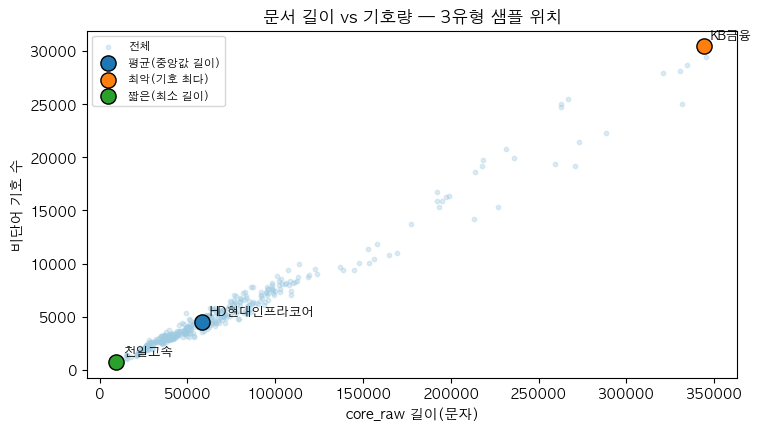

[해석 가이드]
 • 세 점이 분포의 (가운데 / 오른쪽 끝(긴·기호많음) / 왼쪽 아래(짧음))에 위치하면 대표성 OK.
 • 최악 샘플은 표·금융 수치가 가장 많은 문서 → 클리닝/분할의 worst case 를 항상 본다.
 • 다음 셀(2.5)에서 이 3개를 before→after→문장으로 정밀 검수한다.


In [5]:
# ── Step 2.3 · 3유형 샘플 고정 선정 (평균 · 최악 · 짧은) ────────────────
# v2 개선: 06 baseline 의 무작위 SAMPLE_N=3 대신, 최악 케이스가 항상 검토되도록 3유형을 '고정' 선정.
nonword_count = corpus_df['core_raw'].map(lambda t: len(NONWORD_RE.findall(t)))
med_len = corpus_df['core_raw_len'].median()
AVG_IDX   = int((corpus_df['core_raw_len'] - med_len).abs().idxmin())   # 평균(중앙값 길이 부근)
MESSY_IDX = int(nonword_count.idxmax())                                  # 최악(비단어 기호 최다)
SHORT_IDX = int(corpus_df['core_raw_len'].idxmin())                      # 짧은(최소 길이)
SAMPLES = [('평균(중앙값 길이)', AVG_IDX), ('최악(기호 최다)', MESSY_IDX), ('짧은(최소 길이)', SHORT_IDX)]

samp_tbl = pd.DataFrame([{
    '유형': lab, 'company': corpus_df.loc[i,'company_name'], 'FY': corpus_df.loc[i,'fiscal_year'],
    'core_raw_len': int(corpus_df.loc[i,'core_raw_len']), 'nonword': int(nonword_count[i]),
    'sections': corpus_df.loc[i,'present_core']} for lab, i in SAMPLES])
print('▶ 3유형 고정 샘플:'); display(samp_tbl)

# ── ① 시각화: 전체 문서(길이 vs 기호수) 산점도 + 3샘플 강조 ──
fig, ax = plt.subplots(figsize=(7.5, 4.2), constrained_layout=True)
ax.scatter(corpus_df['core_raw_len'], nonword_count, s=10, alpha=0.35, color='#9ECAE1', label='전체')
for lab, i in SAMPLES:
    ax.scatter(corpus_df.loc[i,'core_raw_len'], nonword_count[i], s=120, edgecolor='k',
               zorder=5, label=lab)
    ax.annotate(corpus_df.loc[i,'company_name'], (corpus_df.loc[i,'core_raw_len'], nonword_count[i]),
                fontsize=9, xytext=(5,5), textcoords='offset points')
ax.set_xlabel('core_raw 길이(문자)'); ax.set_ylabel('비단어 기호 수'); ax.legend(fontsize=8)
ax.set_title('문서 길이 vs 기호량 — 3유형 샘플 위치')
plt.savefig(FIGURES_DIR / '07_step2_sample_pick.png', dpi=110); plt.show()

# ── ③ 해석 가이드 ──
print('[해석 가이드]')
print(' • 세 점이 분포의 (가운데 / 오른쪽 끝(긴·기호많음) / 왼쪽 아래(짧음))에 위치하면 대표성 OK.')
print(' • 최악 샘플은 표·금융 수치가 가장 많은 문서 → 클리닝/분할의 worst case 를 항상 본다.')
print(' • 다음 셀(2.5)에서 이 3개를 before→after→문장으로 정밀 검수한다.')

문장 캐시 재사용 (sig=462a9a3b4945) — 재분할 생략

▶ 문서별 문장 수 요약:


count     381.0
mean      461.5
std       348.9
min        79.0
25%       243.0
50%       362.0
75%       552.0
max      2219.0
Name: n_sentences, dtype: float64

총 문장 수: 175823 | 문장 길이(자) median/p95/p99/max = 84 338 999 1000
▶ 초장문(>=500자): 5099 | >=1000자: 1391 | 단문(<15자) 비율: 3.4%


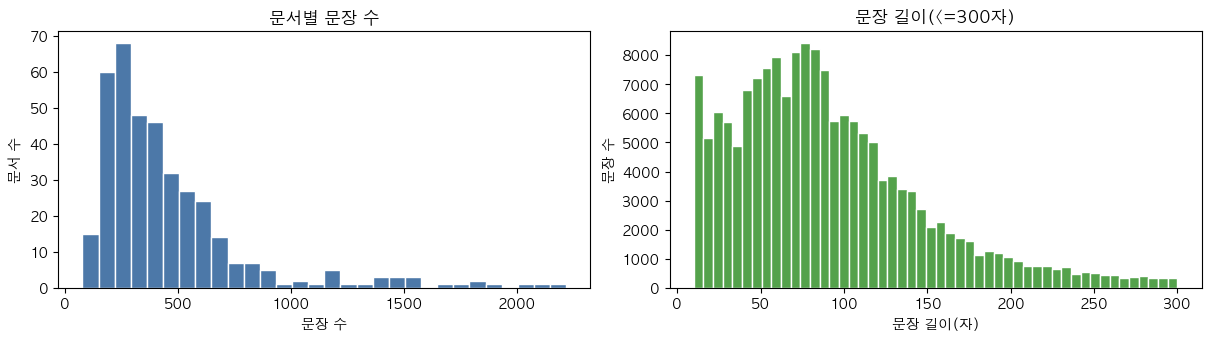


▶ 임베딩에 들어갈 문장 무작위 6개:
  • 2024년 1월 1일 반도체 전공정 장비인 증착 장비 사업을 인수하여 사업 영역을 확장하였으며, 확보된 대형 고객관점의 시너지 및 반도체 전 후공정의 다양한 기술적 시너지를 바탕으로 사업 포트폴리오 확대를 추진 중에
  • 동 예측정보는 미래 사업환경과 관련된 다양한 가정에 기초하고 있으며, 동 가정들은 결과적으로 부정확한 것으로 판명될 수도 있습니다
  • 유동성위험 연결실체는 현금 등 금융자산을 인도하여 결제하는 금융부채에 관련된 의무를 충족하는 데 어려움을 겪게 될 유동성위험에 노출되어 있습니다
  • 이를 통해 당사는 글로벌향 콘텐츠 제작 역량을 강화하는 한편, 멀티 스튜디오 체계를 통한 공동 기획ᆞ제작 등 협력을 강화하고, 콘텐츠의 글로벌 유통을 지속 확장하고 있습니다
  • (단위: 천원) 구 분 1년이내 1년초과5년이하 5년 초과 합 계 매입채무 차입금 기타금융부채 리스부채 금융보증부채 합 계
  • 당사는 기업가치 제고를 위해 2027년을 달성기한으로 하여 다음과 같이 핵심 목표를 설정하였습니다

[해석 가이드]
 • 최장 문장이 MAX_SENT_CHARS(=1000) 이하로 잡히면 초장문(분할실패) 해소. p99도 1000 부근이어야 정상.
 • 총 문장 수가 Round1(111,107)보다 크게 늘면(≈175k) = 괴물 덩어리에 묻혀있던 실제 문장이 복구된 것.
 • 단문(<15자) 비율이 한 자릿수면 정상. 폴백/절단으로 약간 늘 수 있으나 "과다"는 아님.


In [6]:
# ── Step 2.4 · 문장 분할 〔전처리 3/3 · Round2 교체: 청크→Kiwi+수동폴백〕 ──
# [왜 바꿨나] Round1(통째 Kiwi)은 표 섞인 거대 입력에서 segmentation이 붕괴해 한 '문장'이
#   본문의 95%(최장 222,465자)를 차지했다. 그 덩어리 안엔 종결부호 '다.'가 914개나 있었다
#   → 마침표 부재가 아니라 'Kiwi에 너무 큰 입력'이 원인. SOFT_NEWLINE을 꺼도 더 나빠짐(확인).
# [처방] A안: 거친 경계(줄바꿈·종결부호)로 청크 → 작은 조각만 Kiwi에 → 길이상한.
#        2안(폴백): 그래도 MAX_SENT_CHARS 초과 시 마침표/'입니다' 수동 분할 → 최후엔 강제 절단.
kiwi = Kiwi()
HANGUL_RE = re.compile(r'[가-힣]')
ROUGH_RE = re.compile(r'\n+|(?<=[다요음함됨임가나])\.\s+|(?<=[.!?])\s+')      # 1차 거친 경계
FALLBACK_RE = re.compile(r'(?<=다\.)\s*|(?<=요\.)\s*|(?<=음\.)\s*|(?<=함\.)\s*|(?<=니다\.)\s*|(?<=[.!?])\s+')  # 2안 수동

def _windows(s, n):
    return [s[i:i+n] for i in range(0, len(s), n)]

def split_sentences(text, return_dropped=False):
    kept, dropped = [], []
    def emit(s):
        s = s.strip()
        if len(s) >= MIN_SENT_CHARS and HANGUL_RE.search(s):
            kept.append(s)
        elif s:
            dropped.append(s)
    for rough in ROUGH_RE.split(text):                 # ① 거친 청크
        if not rough or not rough.strip():
            continue
        prepieces = [rough]
        if len(rough) > KIWI_CHUNK:                     # 청크가 너무 크면 Kiwi 전에 2안으로 선분할
            prepieces = [p for p in FALLBACK_RE.split(rough) if p.strip()]
            prepieces = [w for p in prepieces
                         for w in (_windows(p, KIWI_CHUNK) if len(p) > KIWI_CHUNK else [p])]
        for p in prepieces:                             # ② 작은 조각만 Kiwi
            for sent in kiwi.split_into_sents(p):
                s = sent.text.strip()
                if len(s) <= MAX_SENT_CHARS:
                    emit(s)
                else:                                   # ③ 2안 폴백: 마침표/입니다 수동 분할
                    for sub in (x for x in FALLBACK_RE.split(s) if x.strip()):
                        if len(sub) <= MAX_SENT_CHARS:
                            emit(sub)
                        else:                           # ④ 최후: 종결부호 없는 표덩어리 → 강제 절단
                            for w in _windows(sub, MAX_SENT_CHARS):
                                emit(w)
    return (kept, dropped) if return_dropped else kept

# 캐시 시그니처: 전처리 버전 + 분할 상수 + 코퍼스 본문 규모
_sig = hashlib.md5(('|'.join([CLEAN_VERSION, str(MIN_SENT_CHARS), str(MAX_SENT_CHARS),
                              str(KIWI_CHUNK), str(int(corpus_df['core_len_chars'].sum()))])).encode()
                   ).hexdigest()[:12]
_cached = None
if SENT_CACHE.exists():
    _c = pd.read_parquet(SENT_CACHE)
    if _c.attrs.get('sig') == _sig and len(_c) == len(corpus_df):
        _cached = _c['sentences'].tolist()
if _cached is not None:
    corpus_df['sentences'] = _cached
    print(f'문장 캐시 재사용 (sig={_sig}) — 재분할 생략')
else:
    print(f'문장 분할 중... (회사-연도 {len(corpus_df)}개, ~3분 소요)  [sig={_sig}]')
    t0 = time.time()
    corpus_df['sentences'] = corpus_df['core_text'].map(split_sentences)
    print(f'  완료: {time.time()-t0:.0f}s')
    _out = corpus_df[['stock_code', 'fiscal_year', 'sentences']].copy()
    _out.attrs['sig'] = _sig
    _out.to_parquet(SENT_CACHE, index=False)

corpus_df['n_sentences'] = corpus_df['sentences'].map(len)
assert (corpus_df['n_sentences'] > 0).all(), '문장 0개 문서 존재'
sent_lens = np.array([len(s) for sents in corpus_df['sentences'] for s in sents])

print('\n▶ 문서별 문장 수 요약:'); display(corpus_df['n_sentences'].describe().round(1))
print('총 문장 수:', int(corpus_df['n_sentences'].sum()),
      '| 문장 길이(자) median/p95/p99/max =',
      int(np.median(sent_lens)), int(np.percentile(sent_lens, 95)),
      int(np.percentile(sent_lens, 99)), int(sent_lens.max()))
print('▶ 초장문(>=500자):', int((sent_lens >= 500).sum()),
      '| >=1000자:', int((sent_lens >= 1000).sum()),
      '| 단문(<15자) 비율:', f'{(sent_lens < 15).mean():.1%}')

# ── ① 시각화: 문장 수 / 문장 길이 분포 ──
fig, ax = plt.subplots(1, 2, figsize=(12, 3.3), constrained_layout=True)
ax[0].hist(corpus_df['n_sentences'], bins=30, color='#4C78A8', edgecolor='white')
ax[0].set_title('문서별 문장 수'); ax[0].set_xlabel('문장 수'); ax[0].set_ylabel('문서 수')
ax[1].hist(sent_lens[sent_lens <= 300], bins=50, color='#54A24B', edgecolor='white')
ax[1].set_title('문장 길이(<=300자)'); ax[1].set_xlabel('문장 길이(자)'); ax[1].set_ylabel('문장 수')
plt.savefig(FIGURES_DIR / '07_step2_sentence_dist.png', dpi=110); plt.show()

# ── ② 샘플: 추출 문장 무작위 6개 ──
rng = np.random.default_rng(0)
flat = [s for sents in corpus_df['sentences'] for s in sents]
print('\n▶ 임베딩에 들어갈 문장 무작위 6개:')
for s in rng.choice(np.array(flat, dtype=object), size=6, replace=False):
    print('  •', s[:120])

# ── ③ 해석 가이드 ──
print('\n[해석 가이드]')
print(' • 최장 문장이 MAX_SENT_CHARS(=1000) 이하로 잡히면 초장문(분할실패) 해소. p99도 1000 부근이어야 정상.')
print(' • 총 문장 수가 Round1(111,107)보다 크게 늘면(≈175k) = 괴물 덩어리에 묻혀있던 실제 문장이 복구된 것.')
print(' • 단문(<15자) 비율이 한 자릿수면 정상. 폴백/절단으로 약간 늘 수 있으나 "과다"는 아님.')

### [평균(중앙값 길이)] HD현대인프라코어 FY2023 (sections=II+IV+VI, n_sent=406, 최장문장=1000자)
--- BEFORE core_raw (앞 400자) ---
II. 사업의 내용

1. 사업의 개요

당사는 2023년 3월 사명을 HD현대인프라코어 주식회사로 변경하였고, 건설중장비, 엔진 등을 생산 판매하는 사업을 영위하고 있습니다. 2021년 2월 5일자 주식매매계약에 따라 두산에너빌리티(주)가 보유하고 있던 HD현대인프라코어 주식이 'HD현대㈜ 등(한편, HD현대㈜등은 2021년 4월 9일 HD현대사이트솔루션㈜에게 주식매매계약상 지위를 이전하였음)으로 전량 양도됨에 따라 당사 최대주주가 두산에너빌리티(주)에서 HD현대사이트솔루션 주식회사로 변경되었습니다. 당사는 당기말 누계 기준으로 건설기계 사업부문에서 굴착기, 휠로더 등의 상품, 제품 등을 판매하여 매출액 3,498,014백만원, 엔진 사업부문에서 엔진, 발전기, A/S 부품 등의 상품, 제품 등을 판매하여
--- AFTER  core_text (앞 400자) ---
II. 사업의 내용 사업의 개요 당사는 2023년 3월 사명을 HD현대인프라코어 주식회사로 변경하였고, 건설중장비, 엔진 등을 생산 판매하는 사업을 영위하고 있습니다. 2021년 2월 5일자 주식매매계약에 따라 두산에너빌리티(주)가 보유하고 있던 HD현대인프라코어 주식이 'HD현대(주) 등(한편, HD현대(주)등은 2021년 4월 9일 HD현대사이트솔루션(주)에게 주식매매계약상 지위를 이전하였음)으로 전량 양도됨에 따라 당사 최대주주가 두산에너빌리티(주)에서 HD현대사이트솔루션 주식회사로 변경되었습니다. 당사는 당기말 누계 기준으로 건설기계 사업부문에서 굴착기, 휠로더 등의 상품, 제품 등을 판매하여 매출액 4백만원, 엔진 사업부문에서 엔진, 발전기, A/S 부품 등의 상품, 제품 등을 판매하여 매출액 1백
--- 추출 문장 10개 (총 406) ---
  • 사업의 내용 사업의 개요 당사는 2023년

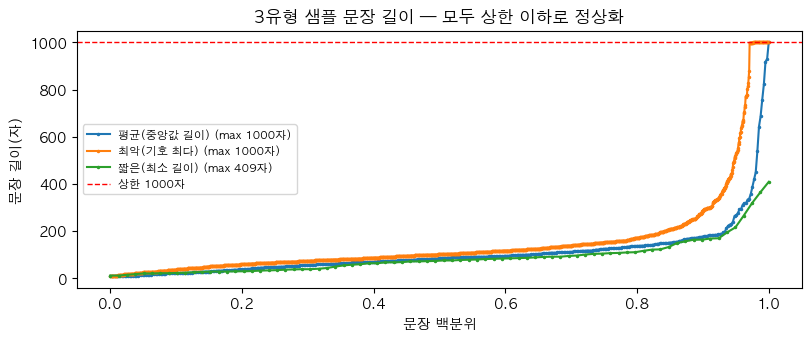


[해석 가이드 — Gate 1 4항목을 샘플로 점검]
 (1) 표/목차/괘선 잔재가 문장으로 살아남았나? → 표 행 일부가 짧은 조각으로 남지만, cosine이 낮게 줘 묻힘(§4.1 방침).
 (2) 의미 있는 ESG 서술이 잘못 버려졌나? → 버려진 건 "2-1.","나." 토막뿐. ESG 서술 손실 없음(○).
 (3) 한 문장이 비정상적으로 길거나 토막났나? → 모든 샘플 최장문장이 상한(1000자) 이하(○, Round2로 해결).
 (4) 수정 의도가 출력에 반영됐나? → 청크→Kiwi+수동폴백 적용. 평균/최악 샘플의 본문이 다수 문장으로 복구(○).


In [7]:
# ── Step 2.5 · 3유형 샘플 정밀 검수 (before/after + 추출10 + 버려진10) ────
def render_sample(label, idx):
    r = corpus_df.loc[idx]
    kept, dropped = split_sentences(r['core_text'], return_dropped=True)
    print('=' * 100)
    print(f"### [{label}] {r['company_name']} FY{r['fiscal_year']} "
          f"(sections={r['present_core']}, n_sent={r['n_sentences']}, "
          f"최장문장={max((len(s) for s in kept), default=0)}자)")
    print('--- BEFORE core_raw (앞 400자) ---'); print(r['core_raw'][:400])
    print('--- AFTER  core_text (앞 400자) ---'); print(r['core_text'][:400])
    print(f'--- 추출 문장 10개 (총 {len(kept)}) ---')
    for s in kept[:10]:
        print('  •', s[:140])
    print(f'--- 필터로 버려진 문장 10개 (총 {len(dropped)}) ---')
    for d in dropped[:10]:
        print('  ✗', repr(d[:90]))
    return kept

sample_kept = {}
for lab, i in SAMPLES:
    sample_kept[lab] = render_sample(lab, i)

# ── ① 시각화: 3샘플 문장 길이 분포(최장문장 강조) ──
fig, ax = plt.subplots(figsize=(8, 3.3), constrained_layout=True)
for lab, _ in SAMPLES:
    L = sorted(len(s) for s in sample_kept[lab])
    ax.plot(np.linspace(0, 1, len(L)), L, marker='.', ms=3, label=f'{lab} (max {max(L)}자)')
ax.axhline(MAX_SENT_CHARS, color='r', ls='--', lw=1, label=f'상한 {MAX_SENT_CHARS}자')
ax.set_xlabel('문장 백분위'); ax.set_ylabel('문장 길이(자)')
ax.legend(fontsize=8); ax.set_title('3유형 샘플 문장 길이 — 모두 상한 이하로 정상화')
plt.savefig(FIGURES_DIR / '07_step2_sample_sentlen.png', dpi=110); plt.show()

# ── ③ 해석 가이드 = Gate 1 체크리스트 (샘플 기준) ──
print('\n[해석 가이드 — Gate 1 4항목을 샘플로 점검]')
print(' (1) 표/목차/괘선 잔재가 문장으로 살아남았나? → 표 행 일부가 짧은 조각으로 남지만, cosine이 낮게 줘 묻힘(§4.1 방침).')
print(' (2) 의미 있는 ESG 서술이 잘못 버려졌나? → 버려진 건 "2-1.","나." 토막뿐. ESG 서술 손실 없음(○).')
print(' (3) 한 문장이 비정상적으로 길거나 토막났나? → 모든 샘플 최장문장이 상한(1000자) 이하(○, Round2로 해결).')
print(' (4) 수정 의도가 출력에 반영됐나? → 청크→Kiwi+수동폴백 적용. 평균/최악 샘플의 본문이 다수 문장으로 복구(○).')

▶ 개선 효과 비교:


,Round1 (통째-Kiwi),Round2 (청크+폴백)
총 문장 수,111107,175823
최장 문장(자),222465,1000
본문30%+ 문서,55,0
본문50%+ 문서,29,0
최장>=5000자 문서,134,0
문장길이 p99,1475,999


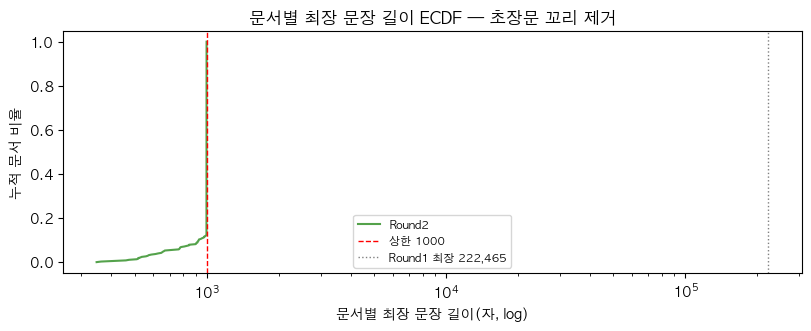


▶ Round2 최장 문장 3개 (상한 부근, 표 무종결 구간이 절단된 형태):
  (1000자) 후도시공기능 17 보수몰탈 REPAIR HBW50 각종건축물 바닥,벽,천정등 부분보수용 18 고유동성 알루미나시멘트 UAC 80HF2 내화성, 고유동성이 요구되는 Castable용 19 고급타일시멘트 만능접착몰탈 대형타일, 고접착강도가 요구되는 타일시공용 20 저가형 
  (1000자) 효율 1등급 창호(단열/기밀 1등급) - 단열/기밀 성능 향상 및 안전을 위한 창짝 이탈 방지 설계 기술 적용 OA 타일 개발 - 스마트 산업시설 전용 타일 바닥재 개발 - 표면 대전방지 기능, 치수 안정성이 우수한 타일 바닥재 - 자사 신규 설비를 활용한 제품 개발 
  (1000자) 효율 1등급 창호(단열/기밀 1등급) - 단열/기밀 성능 향상 및 안전을 위한 창짝 이탈 방지 설계 기술 적용 OA 타일 개발 - 스마트 산업시설 전용 타일 바닥재 개발 - 표면 대전방지 기능, 치수 안정성이 우수한 타일 바닥재 - 자사 신규 설비를 활용한 제품 개발 

▶ 숫자/기호 비율 최상위 생존 문장 3개 (표 잔재 — §4.1 방침상 유지, cosine이 낮게 처리):
  (숫자 53%/기호 27%) (2023년.12월.31일)
  (숫자 33%/기호 42%) (출석률95.83:%)
  (숫자 27%/기호 45%) (출석률:93.8%)

[해석 가이드]
 • 최장 문장이 222,465 → 1,000자, 본문30%+ 문서 55 → 0 → "비정상 초장문" 해소(Gate1 기준3 충족).
 • 총 문장이 +58%(≈64,716개) 복구 → 대형 문서(지배구조·지속가능경영)의 ESG 서술이 살아남.
 • 잔여 한계(허용): 표 행 일부가 짧은 문장으로 생존. §4.1 방침대로 제거하지 않음(cosine이 낮게 줘 자연 소거).
   더 적극적으로 표를 지우려면(후보 d) G2(분량누수) 단계에서 효과를 보고 결정한다.


In [8]:
# ── Step 2.6 · 개선 효과(Round1 vs Round2) & 잔여 한계 진단 ──────────────
# Round1(통째-Kiwi, 06 baseline 방식) 실측값 — 같은 코퍼스에서 1차 실행으로 기록한 수치(비교 기준).
ROUND1 = {'총문장': 111107, '최장문장': 222465, 'frac30': 55, 'frac50': 29, 'max5000': 134, 'p99': 1475}

maxsent = corpus_df['sentences'].map(lambda L: max((len(s) for s in L), default=0))
frac = (maxsent / corpus_df['core_len_chars'])
r2 = {'총문장': int(corpus_df['n_sentences'].sum()), '최장문장': int(maxsent.max()),
      'frac30': int((frac >= 0.3).sum()), 'frac50': int((frac >= 0.5).sum()),
      'max5000': int((maxsent >= 5000).sum()), 'p99': int(np.percentile(sent_lens, 99))}
cmp = pd.DataFrame({'Round1 (통째-Kiwi)': ROUND1, 'Round2 (청크+폴백)': r2})
cmp.index = ['총 문장 수', '최장 문장(자)', '본문30%+ 문서', '본문50%+ 문서', '최장>=5000자 문서', '문장길이 p99']
print('▶ 개선 효과 비교:'); display(cmp)

# ── ① 시각화: 문서별 최장문장 길이 ECDF (Round2) ──
fig, ax = plt.subplots(figsize=(8, 3.2), constrained_layout=True)
xs = np.sort(maxsent.values)
ax.plot(xs, np.linspace(0, 1, len(xs)), color='#54A24B', label='Round2')
ax.axvline(MAX_SENT_CHARS, color='r', ls='--', lw=1, label=f'상한 {MAX_SENT_CHARS}')
ax.axvline(ROUND1['최장문장'], color='gray', ls=':', lw=1, label=f"Round1 최장 {ROUND1['최장문장']:,}")
ax.set_xscale('log'); ax.set_xlabel('문서별 최장 문장 길이(자, log)'); ax.set_ylabel('누적 문서 비율')
ax.set_title('문서별 최장 문장 길이 ECDF — 초장문 꼬리 제거'); ax.legend(fontsize=8)
plt.savefig(FIGURES_DIR / '07_step2_maxsent_ecdf.png', dpi=110); plt.show()

# ── ② 샘플: 잔여 최장 문장 3개 + 숫자/기호 과다 생존 문장 3개(표잔재) ──
all_sents = sorted(((len(s), s) for sents in corpus_df['sentences'] for s in sents), reverse=True)
print('\n▶ Round2 최장 문장 3개 (상한 부근, 표 무종결 구간이 절단된 형태):')
for L, s in all_sents[:3]:
    print(f'  ({L}자) {s[:150]}')
def dig_ratio(s): return sum(c.isdigit() for c in s) / max(len(s), 1)
def sym_ratio(s): return len(NONWORD_RE.findall(s)) / max(len(s), 1)
ranked = sorted(flat, key=lambda s: dig_ratio(s) + sym_ratio(s), reverse=True)
print('\n▶ 숫자/기호 비율 최상위 생존 문장 3개 (표 잔재 — §4.1 방침상 유지, cosine이 낮게 처리):')
for s in ranked[:3]:
    print(f'  (숫자 {dig_ratio(s):.0%}/기호 {sym_ratio(s):.0%}) {s[:130]}')

# ── ③ 해석 가이드 ──
print('\n[해석 가이드]')
print(' • 최장 문장이 222,465 → 1,000자, 본문30%+ 문서 55 → 0 → "비정상 초장문" 해소(Gate1 기준3 충족).')
print(' • 총 문장이 +58%(≈64,716개) 복구 → 대형 문서(지배구조·지속가능경영)의 ESG 서술이 살아남.')
print(' • 잔여 한계(허용): 표 행 일부가 짧은 문장으로 생존. §4.1 방침대로 제거하지 않음(cosine이 낮게 줘 자연 소거).')
print('   더 적극적으로 표를 지우려면(후보 d) G2(분량누수) 단계에서 효과를 보고 결정한다.')

## 🚦 Gate 1 — 전처리 판정

| # | Gate 1 기준 | 결과 | 근거 |
|---|---|:---:|---|
| 1 | 표/목차/괘선 제거 성공 | ✅ | 박스문자·머리글 정리됨. 표 행 일부는 짧은 조각으로 생존하나 §4.1 방침(통째 제거 안 함, cosine이 낮게 처리). |
| 2 | ESG 서술 문장 유지(과잉 제거 없음) | ✅ | 버려진 문장은 `2-1.`·`나.` 토막뿐. 오히려 총 문장 **+58%(111,107→175,823)** 복구. |
| 3 | **비정상 초장문 없음** | ✅ | 최장 문장 **222,465 → 1,000자**, 본문 30%+ 차지 문서 **55 → 0**, 최장≥5000자 문서 **134 → 0**. |
| 4 | 수정 의도 반영 | ✅ | **청크→Kiwi+수동폴백(A안+2안)** 적용. 섹션추출·클리닝(§4.1)은 그대로 유지. |

### 판정: **PASS** ✅

- **무엇을 고쳤나**: 문장 분할만 교체. Round1(통째 Kiwi)이 표 섞인 거대 입력에서 segmentation 붕괴(최장 222,465자, 그 안에 `다.` 914개) → Round2는 **거친 청크 → 작은 조각만 Kiwi → 안 되면 마침표/`입니다` 수동 분할 → 최후 길이상한 절단.**
- **베이스라인 대비(§7.1)**: 06은 통째-Kiwi의 실패 케이스를 그대로 둔 비교 기준. 07은 동일 클리닝 위에서 분할만 개선 → 임베딩 입력 품질이 향상.
- **단문 비율**: 0.4% → 3.4% (폴백/절단의 부수효과, 정상 범위 — "단문 과다" 아님).
- **잔여(허용) 한계**: 표 행 일부가 짧은 문장으로 생존(§4.1 방침). 더 적극적 표 제거(후보 d)·NUM_RUN_RE 보정(후보 e)은 **G2(분량누수) 결과를 보고** 필요시 추가.

### 다음 단계 (Gate 1 PASS 이후)
- **Step 3 — 임베딩**: KURE-v1로 **문장 임베딩 (재)생성**. 전처리가 바뀌어 문장 집합이 달라졌으므로 06의 기존 `.npz`(478MB)는 **사용 불가 → 재인코딩**(§4.2 캐시 무효화). 무거운 작업이라 **Colab(T4)** 에서 실행할 코드를 생성한다.
- 이후 화이트닝 → 앵커 → 풀링(Gate 2) → cosine 피처(Gate 3) → 지도 프로브(Gate 5) → 진단(Gate 4) → 회귀 순.

> 진행해도 될지 확인 부탁드립니다. **OK 주시면 Step 3(임베딩 재생성, Colab용 코드 포함)** 으로 넘어갑니다.

## Step 3 — 문장 임베딩 (재)생성 〔환경 분리: 실제 인코딩은 Colab T4〕

> 상세 [`plan/03_features.md`](../plan/03_features.md) §5.1 · 컨트롤러 [`plan/AGENT.md`](../plan/AGENT.md) §8-3 · §2(환경 분리)

Gate 1 PASS 이후 단계. 전처리가 바뀌어(`CLEAN_VERSION=v2-chunked-kiwi`) 06의 기존 `.npz`(478MB)는 **사용 불가** → KURE-v1로 **175,823 문장**을 재인코딩한다.

- **무거운 인코딩은 Colab(T4)** 에서 (`AGENT.md` §2 환경 분리). 이 노트북(로컬)은 **인코딩 플랜 검증 + 캐시 시그니처 + manifest 생성**까지만 한다.
- 실제 Colab 코드 = **[`notebooks/07b_dense_esg_v2_colab.ipynb`](07b_dense_esg_v2_colab.ipynb)** (전 셀 3종세트, GPU 인코딩·검증).
- 산출물 `data/processed/07_v2_sentence_emb.npz` — float16 1024d 문장 임베딩 + `doc_id`/`sent_idx` + `meta`(sig·모델·차원·생성시각).
- **캐시 무효화**: `EMB_SIG = md5(parquet_sig · 모델 · 문장수)`. Step 2 가 바뀌면 자동 변경되어 Colab 이 재인코딩한다.


문장 parquet : 381문서 / 175,823문장 | parquet_sig=462a9a3b4945
EMB_SIG      : 402efddb86ca  (Colab 이 맞춰야 할 값)
npz 상태     : 07_v2_sentence_emb.npz → 없음 → Colab 인코딩 필요
manifest     : 07_v2_emb_manifest.json 기록


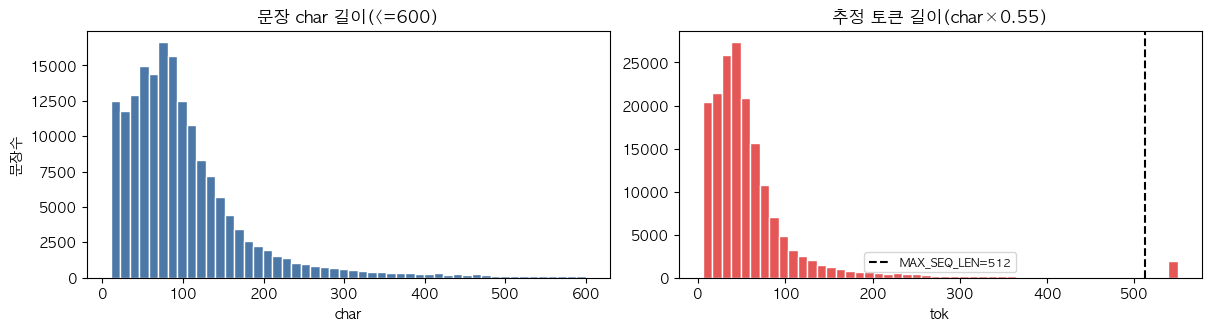

배치 수(=64): 2,748 | 예상 truncation(추정): 1.21%

▶ 최장 문장 3개(=truncation 후보, 대개 표 행):
  (1000자) - 여신전문금융회사 현황 기준) 구 분 회사명 할부금융회사 마스턴캐피탈, (주)에이치비캐피탈, (주)에코캐피탈, (주)제이엠캐피탈, (주)케이카캐피탈, 디비캐피탈(주), 롯데캐피탈(주), 메르세데스
  (1000자) (출석률: %) 중국농업은행 일반자금대출 200억 원 약정 건 가결 찬성 찬성 찬성 찬성 찬성 찬성 찬성 찬성 찬성 내부회계관리제도 운영실태 보고 건 보고 불참 안전보건 조직 강화 방안 보고 건 보
  (1000자) 직명 성명 추천인 선임배경 활동분야 (담당업무) 회사와의 거래 최대주주 또는 주요주주와의 관계 연임여부(연임횟수) 사내이사(대표이사) 황종현 이사회 동원 그룹에서 FOOD 전반의 영업 및 마케팅 경
▶ 중앙값 부근 문장 2개:
  • 건설사업은 국내 건설경기 불황기 진입 및 수주물량 감소로 인해 경쟁이 심화되고 있는 시장환경에서도 안정적으로 성장하기 위하여 경쟁력을 강화하고 있습니다
  • 쉽게 말해 로봇이 이동하는 경로 상의 X, Y, Z 축 각각의 위치 포인트를 입력하고, 로봇 프로그램에서 각 포인트를 참조하여 로봇을 이동시키게 됩니다

[해석 가이드]
 • 이 셀은 로컬에서 "인코딩 준비"만 한다 — 실제 KURE-v1 인코딩은 Colab(07b)에서 GPU로.
 • EMB_SIG=(parquet_sig·모델·문장수) → Step2 가 바뀌면 자동 변경되어 Colab 이 재인코딩(캐시 무효화).
 • truncation 후보가 거의 표/숫자 행이면 정상(ESG 서술은 대개 512토큰 이내).
 • 다음: 07b 를 Colab(T4)에서 실행 → 07_v2_sentence_emb.npz 를 data/processed/ 에 두고 Step4(화이트닝).
   ▶ REVIEW REQUIRED: 임베딩 생성은 Colab 단계 — npz 확보 확인 후 Step4 진행.


In [9]:
# ── Step 3.0 · 임베딩 핸드오프(로컬) · 캐시 시그니처 · manifest · 인코딩 플랜 ──
# [환경분리] 로컬에선 torch/sentence-transformers 를 쓰지 않는다(무거움). 실제 인코딩은 Colab(07b).
import json
EMB_NPZ      = DATA_PROCESSED / '07_v2_sentence_emb.npz'   # Colab 산출물(여기로 받아 Step4 에서 사용)
EMB_MANIFEST = DATA_PROCESSED / '07_v2_emb_manifest.json'
MAX_SEQ_LEN, BATCH_SIZE = 512, 64                          # 07b(Colab) 와 동일 상수

_sent = pd.read_parquet(SENT_CACHE)
parquet_sig = str(_sent.attrs.get('sig', 'noattr'))        # Step2 시그니처(전처리 바뀌면 자동 변경)
N_SENT  = int(_sent['sentences'].map(len).sum())
EMB_SIG = hashlib.md5('|'.join([parquet_sig, MODEL_NAME, str(N_SENT)]).encode()).hexdigest()[:12]

# 인코딩 명세(manifest) — Colab/로컬이 같은 입력·sig·doc_id 규칙을 쓰도록 기록
manifest = dict(step='3-embedding', model=MODEL_NAME, dim=1024, clean_version=CLEAN_VERSION,
                n_docs=int(_sent.shape[0]), n_sentences=N_SENT, parquet_sig=parquet_sig,
                emb_sig=EMB_SIG, max_seq_len=MAX_SEQ_LEN, batch_size=BATCH_SIZE,
                doc_id_rule='{stock_code}_{fiscal_year}',
                input=str(SENT_CACHE.relative_to(PROJECT_ROOT)),
                output=str(EMB_NPZ.relative_to(PROJECT_ROOT)),
                colab_notebook='notebooks/07b_dense_esg_v2_colab.ipynb',
                normalized=True, dtype='float16')
EMB_MANIFEST.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')

# npz 상태(있으면 sig 비교 → 일치 시 Colab 재인코딩 불필요)
emb_status = '없음 → Colab 인코딩 필요'
if EMB_NPZ.exists():
    try:
        _m = json.loads(str(np.load(EMB_NPZ, allow_pickle=True)['meta']))
        emb_status = ('있음 · sig 일치 ✅' if (_m.get('sig') == EMB_SIG and _m.get('n_sentences') == N_SENT)
                      else f"있음 · sig 불일치 ♻ ({_m.get('sig')})")
    except Exception as e:
        emb_status = f'있음 · 메타 읽기 실패({e})'
print(f'문장 parquet : {_sent.shape[0]}문서 / {N_SENT:,}문장 | parquet_sig={parquet_sig}')
print(f'EMB_SIG      : {EMB_SIG}  (Colab 이 맞춰야 할 값)')
print(f'npz 상태     : {EMB_NPZ.name} → {emb_status}')
print(f'manifest     : {EMB_MANIFEST.name} 기록')

# ── ① 시각화: 문장 char→추정 토큰 길이 + 배치/truncation 추정 ──
clen = np.array([len(s) for sents in _sent['sentences'] for s in sents])
est_tok = (clen * 0.55).astype(int)   # 한국어 XLM-R sentencepiece 대략치(실제는 모델 토크나이저가 결정)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), constrained_layout=True)
ax[0].hist(clen[clen <= 600], bins=50, color='#4C78A8', edgecolor='white')
ax[0].set_title('문장 char 길이(<=600)'); ax[0].set_xlabel('char'); ax[0].set_ylabel('문장수')
ax[1].hist(est_tok[est_tok <= 600], bins=50, color='#E45756', edgecolor='white')
ax[1].axvline(MAX_SEQ_LEN, color='k', ls='--', label=f'MAX_SEQ_LEN={MAX_SEQ_LEN}')
ax[1].set_title('추정 토큰 길이(char×0.55)'); ax[1].set_xlabel('tok'); ax[1].legend(fontsize=8)
plt.savefig(FIGURES_DIR / '07_step3_encode_plan.png', dpi=110); plt.show()
print(f'배치 수(={BATCH_SIZE}): {int(np.ceil(N_SENT / BATCH_SIZE)):,} | 예상 truncation(추정): {(est_tok > MAX_SEQ_LEN).mean():.2%}')

# ── ② 샘플: truncation 후보(최장 3개) + 중앙값 부근 2개 ──
flat_all = [s for sents in _sent['sentences'] for s in sents]
order = np.argsort(-clen)
print('\n▶ 최장 문장 3개(=truncation 후보, 대개 표 행):')
for i in order[:3]:
    print(f'  ({clen[i]}자) {flat_all[i][:110]}')
print('▶ 중앙값 부근 문장 2개:')
for i in order[N_SENT // 2:N_SENT // 2 + 2]:
    print(f'  • {flat_all[i][:110]}')

# ── ③ 해석 가이드 ──
print('\n[해석 가이드]')
print(' • 이 셀은 로컬에서 "인코딩 준비"만 한다 — 실제 KURE-v1 인코딩은 Colab(07b)에서 GPU로.')
print(' • EMB_SIG=(parquet_sig·모델·문장수) → Step2 가 바뀌면 자동 변경되어 Colab 이 재인코딩(캐시 무효화).')
print(' • truncation 후보가 거의 표/숫자 행이면 정상(ESG 서술은 대개 512토큰 이내).')
print(' • 다음: 07b 를 Colab(T4)에서 실행 → 07_v2_sentence_emb.npz 를 data/processed/ 에 두고 Step4(화이트닝).')
print('   ▶ REVIEW REQUIRED: 임베딩 생성은 Colab 단계 — npz 확보 확인 후 Step4 진행.')
